# Growth analysis

## Part A — How much did prices grow?

Compare the average of the four 2019 medians with the latest four-quarter average for houses and units separately. The tables and charts use the first-published prices for the main results and a separate revised series for the D08 check. All analysis data come from the processed CSVs.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

repo_root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
processed_dir = repo_root / "data/processed"
growth = pd.read_csv(processed_dir / "lga_growth.csv")
geographies = pd.read_csv(processed_dir / "dim_lga.csv")
dates = pd.read_csv(processed_dir / "dim_date.csv", parse_dates=["quarter_date"])
sales = pd.read_csv(processed_dir / "fact_sales.csv", parse_dates=["quarter_date"])
last_quarter = dates["quarter_date"].max().to_period("Q")
end_label = last_quarter.end_time.strftime("%B %Y")
dwelling_types = ["house", "unit"]
percent = "{:.1%}"

def show_table(table, formats=None):
    """Format values for reading while retaining full precision in the data."""
    display(table.style.hide(axis="index").format(formats or {}, na_rep="—"))

print(f"Sales coverage: {dates['quarter_label'].iloc[0]} to {last_quarter.year} Q{last_quarter.quarter}")
print(f"Sydney CPI rose {growth['cpi_ratio'].iloc[0] - 1:.1%} between the two price windows.")

Sales coverage: 2019 Q1 to 2026 Q1
Sydney CPI rose 24.1% between the two price windows.


### Benchmarks for Greater Sydney and the rings

Use each published aggregate series as its own benchmark. Show the total nominal increase, its annualised rate and the total increase after Sydney CPI.

In [2]:
benchmark_order = geographies.loc[geographies["geo_level"].ne("lga"), ["lga", "sort_order"]]
benchmarks = growth.merge(benchmark_order, on="lga", validate="many_to_one").sort_values(
    ["sort_order", "dwelling_type"]
)
benchmark_values = benchmarks.set_index(["lga", "dwelling_type"])
benchmark_columns = {
    "lga": "Geography", "dwelling_type": "Dwelling", "growth_pct": "Nominal",
    "growth_annualised": "Annualised", "growth_pct_real": "Real",
}
show_table(
    benchmarks[list(benchmark_columns)].rename(columns=benchmark_columns),
    {name: percent for name in ["Nominal", "Annualised", "Real"]},
)

Geography,Dwelling,Nominal,Annualised,Real
Greater Sydney,house,67.5%,8.6%,34.9%
Greater Sydney,unit,18.1%,2.7%,-4.8%
Inner Ring,house,51.9%,6.9%,22.3%
Inner Ring,unit,22.7%,3.3%,-1.1%
Middle Ring,house,71.8%,9.0%,38.4%
Middle Ring,unit,14.5%,2.2%,-7.7%
Outer Ring,house,67.5%,8.6%,34.9%
Outer Ring,unit,30.3%,4.3%,5.0%


### Rank houses and units separately

Rank each dwelling type by first-published nominal growth. Real growth has the same order because every LGA uses the same positive CPI ratio. A positive revision rank change means the LGA moved down the ranking. Count low-sales quarters across the baseline and latest windows.

In [3]:
lga_growth = growth.loc[growth["geo_level"].eq("lga")].copy()
lga_growth["low_sales_quarters"] = (
    lga_growth["baseline_low_sales_quarters"] + lga_growth["latest_low_sales_quarters"]
)
ranked = lga_growth.dropna(subset=["growth_rank"]).sort_values(["dwelling_type", "growth_rank", "lga"])
ranking_columns = {
    "growth_rank": "Rank", "lga": "LGA", "region": "Ring", "price_2019": "2019 price",
    "price_latest": "Latest price", "growth_pct": "Nominal", "growth_annualised": "Annualised",
    "growth_pct_real": "Real", "low_sales_quarters": "Low-sales quarters",
    "rank_change_rev": "Revision rank change",
}
ranking_formats = {
    "Rank": "{:.0f}", "2019 price": "${:,.0f}", "Latest price": "${:,.0f}", "Nominal": percent,
    "Annualised": percent, "Real": percent, "Revision rank change": "{:+.0f}",
}
for dwelling in dwelling_types:
    display(Markdown(f"**{dwelling.capitalize()} rankings**"))
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    show_table(series[list(ranking_columns)].rename(columns=ranking_columns), ranking_formats)

excluded = lga_growth.loc[lga_growth["growth_rank"].isna(), ["lga", "dwelling_type", "growth_note"]]
assert excluded[["lga", "dwelling_type"]].values.tolist() == [["Wollondilly", "unit"]]
display(Markdown("**Wollondilly units** — no 2019 baseline (D05)."))

**House rankings**

Rank,LGA,Ring,2019 price,Latest price,Nominal,Annualised,Real,Low-sales quarters,Revision rank change
1,Fairfield,Outer Ring,"$733,000","$1,341,250",83.0%,10.2%,47.4%,0,+0
2,Cumberland,Middle Ring,"$795,750","$1,443,750",81.4%,10.0%,46.2%,0,+0
3,Burwood,Middle Ring,"$1,452,250","$2,621,250",80.5%,9.9%,45.4%,3,+0
4,Canterbury-Bankstown,Middle Ring,"$898,000","$1,620,250",80.4%,9.9%,45.4%,0,+0
5,Ryde,Middle Ring,"$1,486,250","$2,669,250",79.6%,9.8%,44.7%,0,+1
6,Canada Bay,Middle Ring,"$1,784,750","$3,200,250",79.3%,9.8%,44.5%,0,-1
7,Penrith,Outer Ring,"$655,000","$1,150,250",75.6%,9.4%,41.5%,0,+0
8,Parramatta,Middle Ring,"$1,099,250","$1,901,750",73.0%,9.2%,39.4%,0,+3
9,Blacktown,Outer Ring,"$716,000","$1,236,250",72.7%,9.1%,39.1%,0,-1
10,Ku-Ring-Gai,Middle Ring,"$2,008,000","$3,453,000",72.0%,9.1%,38.5%,0,-1


**Unit rankings**

Rank,LGA,Ring,2019 price,Latest price,Nominal,Annualised,Real,Low-sales quarters,Revision rank change
1,Hawkesbury,Outer Ring,"$482,250","$765,750",58.8%,7.7%,27.9%,4,+0
2,Campbelltown,Outer Ring,"$419,250","$661,000",57.7%,7.6%,27.0%,0,+0
3,Central Coast,Outer Ring,"$473,750","$730,500",54.2%,7.2%,24.2%,0,+0
4,Northern Beaches,Outer Ring,"$876,250","$1,295,000",47.8%,6.4%,19.1%,0,+1
5,Penrith,Outer Ring,"$468,750","$690,750",47.4%,6.4%,18.7%,0,+1
6,Randwick,Inner Ring,"$921,250","$1,357,500",47.4%,6.4%,18.7%,0,+1
7,Camden,Outer Ring,"$542,750","$795,500",46.6%,6.3%,18.1%,4,-3
8,Blue Mountains,Outer Ring,"$560,250","$776,250",38.6%,5.4%,11.6%,5,+0
9,Woollahra,Inner Ring,"$1,358,750","$1,878,750",38.3%,5.3%,11.4%,0,+0
10,Sutherland Shire,Outer Ring,"$723,000","$991,500",37.1%,5.2%,10.5%,0,+0


**Wollondilly units** — no 2019 baseline (D05).

### Check how much revisions move the rankings

Use Spearman correlation to compare the two growth rankings over LGAs with values in both series. List every LGA that moves more than three places.

In [4]:
correlation_rows = []
for dwelling in dwelling_types:
    paired = lga_growth.loc[lga_growth["dwelling_type"].eq(dwelling), ["growth_pct", "growth_pct_rev"]].dropna()
    rho = paired["growth_pct"].corr(paired["growth_pct_rev"], method="spearman")
    correlation_rows.append((dwelling, len(paired), rho))
correlations = pd.DataFrame(correlation_rows, columns=["Dwelling", "LGA pairs", "Spearman rho"])
show_table(correlations, {"Spearman rho": "{:.3f}"})

rank_moves = ranked.loc[ranked["rank_change_rev"].abs().gt(3)].copy()
rank_moves["places_moved"] = rank_moves["rank_change_rev"].abs()
rank_moves = rank_moves.sort_values("places_moved", ascending=False)
sensitivity_columns = {
    "lga": "LGA", "dwelling_type": "Dwelling", "growth_pct": "First-published", "growth_pct_rev": "Revised",
    "growth_rank": "First rank", "growth_rank_rev": "Revised rank", "rank_change_rev": "Rank change",
}
show_table(rank_moves[list(sensitivity_columns)].rename(columns=sensitivity_columns), {
    "First-published": percent, "Revised": percent, "First rank": "{:.0f}",
    "Revised rank": "{:.0f}", "Rank change": "{:+.0f}",
})

agreement = correlations.set_index("Dwelling")["Spearman rho"]
woollahra = lga_growth.set_index(["lga", "dwelling_type"]).loc[("Woollahra", "house")]
conclusion = (
    f"Rank agreement was high for both houses (Spearman {agreement['house']:.3f}) "
    f"and units ({agreement['unit']:.3f}). "
    f"Woollahra houses moved from rank {woollahra['growth_rank']:.0f} to {woollahra['growth_rank_rev']:.0f} "
    f"as growth went from {woollahra['growth_pct']:.1%} to {woollahra['growth_pct_rev']:.1%} in the revised estimate. "
    "Woollahra's last place in the first-published house series is therefore sensitive to revisions."
)
display(Markdown(conclusion))

Dwelling,LGA pairs,Spearman rho
house,34,0.934
unit,33,0.992


LGA,Dwelling,First-published,Revised,First rank,Revised rank,Rank change
Woollahra,house,43.0%,64.8%,34,17,-17
Willoughby,house,60.6%,56.7%,22,28,+6
Hawkesbury,house,57.2%,53.0%,26,31,+5
Mosman,house,55.3%,60.0%,28,23,-5


Rank agreement was high for both houses (Spearman 0.934) and units (0.992). Woollahra houses moved from rank 34 to 17 as growth went from 43.0% to 64.8% in the revised estimate. Woollahra's last place in the first-published house series is therefore sensitive to revisions.

### Flag the extremes that need a caveat

Check the five highest and five lowest ranks in each dwelling type for low-sales quarters in either window and revision rank shifts of more than three places. Keep the baseline and latest counts separate so the source of each flag is visible.

In [5]:
ranked = ranked.assign(
    low_sales_caveat=ranked["low_sales_quarters"].gt(0),
    revision_caveat=ranked["rank_change_rev"].abs().gt(3),
)
ranked["has_caveat"] = ranked["low_sales_caveat"] | ranked["revision_caveat"]
extremes = []
for dwelling in dwelling_types:
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    extremes.append(series.head(5).assign(end="Top five"))
    extremes.append(series.tail(5).iloc[::-1].assign(end="Bottom five"))
extremes = pd.concat(extremes, ignore_index=True)
assert len(extremes) == 20
robustness_columns = {
    "dwelling_type": "Dwelling", "end": "Group", "growth_rank": "Rank", "lga": "LGA",
    "baseline_low_sales_quarters": "Low sales in 2019", "latest_low_sales_quarters": "Low sales in latest four",
    "revision_caveat": "Moved >3 places", "has_caveat": "Caveat",
}
show_table(extremes[list(robustness_columns)].rename(columns=robustness_columns), {"Rank": "{:.0f}"})

Dwelling,Group,Rank,LGA,Low sales in 2019,Low sales in latest four,Moved >3 places,Caveat
house,Top five,1,Fairfield,0,0,False,False
house,Top five,2,Cumberland,0,0,False,False
house,Top five,3,Burwood,3,0,False,True
house,Top five,4,Canterbury-Bankstown,0,0,False,False
house,Top five,5,Ryde,0,0,False,False
house,Bottom five,34,Woollahra,0,0,True,True
house,Bottom five,33,North Sydney,0,0,False,False
house,Bottom five,32,Wollondilly,0,0,False,False
house,Bottom five,31,Sydney,0,0,False,False
house,Bottom five,30,Randwick,0,0,False,False


### Chart nominal growth by LGA

Plot one bar per ranked LGA, with the five highest in blue and the Greater Sydney benchmark as a dashed line. Hatch any bar with a low-sales or revision flag.

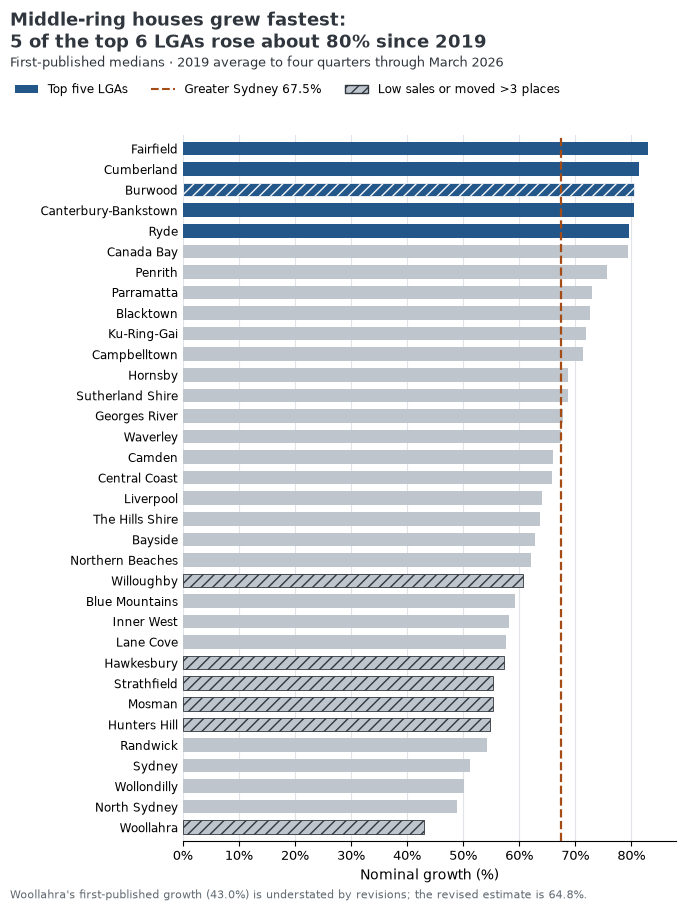

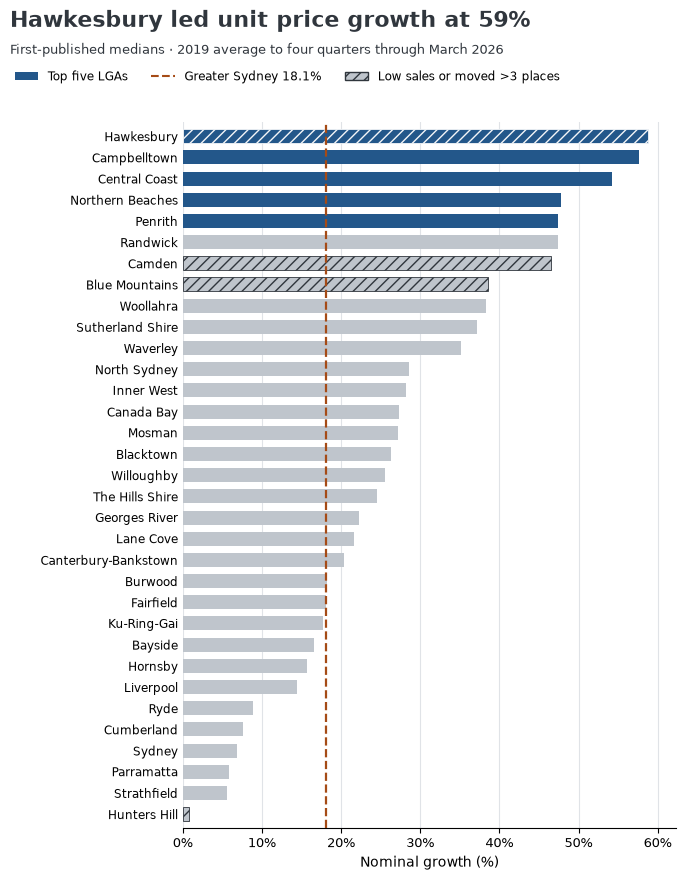

In [6]:
figure_dir = repo_root / "docs/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
blue = "#23578A"
rust = "#A54B16"
light_grey = "#BFC5CC"
ink = "#30363D"
grid_grey = "#E0E3E7"

def save_chart(fig, filename):
    fig.savefig(figure_dir / filename, dpi=150, metadata={"Software": None}, facecolor="white")
    plt.show()
    plt.close(fig)

def add_woollahra_footnote(fig, left):
    """Explain the revision sensitivity using the Woollahra house growth row."""
    note = (
        f"Woollahra's first-published growth ({woollahra['growth_pct']:.1%}) is understated by revisions; "
        f"the revised estimate is {woollahra['growth_pct_rev']:.1%}."
    )
    fig.text(left, 0.015, note, fontsize=8, color="#606870", va="bottom")

def plot_growth_bars(dwelling):
    series = ranked.loc[ranked["dwelling_type"].eq(dwelling)]
    leader = series.iloc[0]
    benchmark = benchmark_values.loc[("Greater Sydney", dwelling), "growth_pct"]
    colors = [blue if rank <= 5 else light_grey for rank in series["growth_rank"]]

    fig, ax = plt.subplots(figsize=(7.2, 9.15))
    fig.subplots_adjust(left=0.28, right=0.965, top=0.852, bottom=0.081)
    title = f"{leader['lga']} led {dwelling} price growth at {leader['growth_pct']:.0%}"
    if dwelling == "house":
        title = "Middle-ring houses grew fastest:\n5 of the top 6 LGAs rose about 80% since 2019"
        fig.text(0.04, 0.989, title, fontsize=13, fontweight="bold", color=ink, va="top")
    else:
        fig.text(0.04, 0.975, title, fontsize=16, fontweight="bold", color=ink, va="top")
    fig.text(0.04, 0.939, f"First-published medians · 2019 average to four quarters through {end_label}",
             fontsize=9.5, color=ink, va="top")
    bars = ax.barh(series["lga"], series["growth_pct"], color=colors, height=0.66)
    for bar, color, has_caveat in zip(bars, colors, series["has_caveat"], strict=True):
        if has_caveat:
            bar.set_hatch("///")
            bar.set_edgecolor("#F4F6F8" if color == blue else ink)
            bar.set_linewidth(0.6)

    ax.axvline(benchmark, color=rust, linestyle="--", linewidth=1.6, zorder=3)
    ax.invert_yaxis()
    ax.set_ylim(len(series) - 0.35, -0.65)
    ax.set_xlim(min(0, series["growth_pct"].min()), 1.06 * max(benchmark, series["growth_pct"].max()))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Nominal growth (%)")
    ax.grid(axis="x", color=grid_grey)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", labelsize=8.3, length=0)
    ax.tick_params(axis="x", labelsize=9)
    legend = [
        Patch(facecolor=blue, label="Top five LGAs"),
        Line2D([0], [0], color=rust, linestyle="--", label=f"Greater Sydney {benchmark:.1%}"),
        Patch(facecolor=light_grey, edgecolor=ink, hatch="///", label="Low sales or moved >3 places"),
    ]
    fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.04, 0.914), ncol=3,
               frameon=False, fontsize=8.5, borderaxespad=0)
    if dwelling == "house":
        add_woollahra_footnote(fig, 0.04)
    save_chart(fig, f"growth_by_lga_{dwelling}.png")

for dwelling in dwelling_types:
    plot_growth_bars(dwelling)

### Chart price indexes for Greater Sydney and each ring

Divide each quarter's first-published median by its own geography and dwelling type's 2019 average, then multiply by 100. Plot houses and units on the same vertical scale so the change in each ring is comparable.

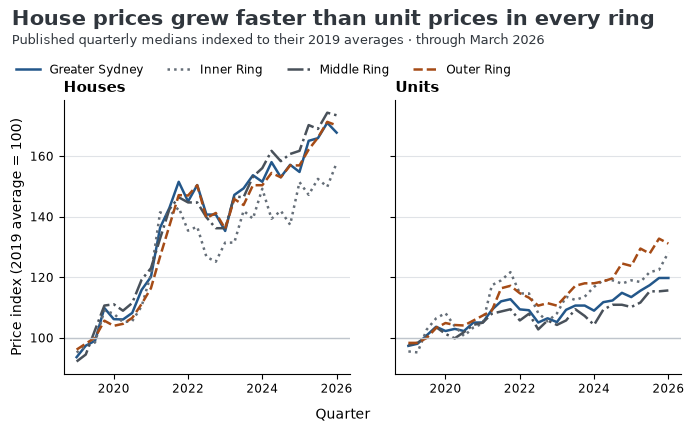

In [7]:
index_rows = sales.merge(
    benchmarks[["lga", "dwelling_type", "price_2019"]], on=["lga", "dwelling_type"], validate="many_to_one",
)
index_rows["price_index"] = 100 * index_rows["median_price"] / index_rows["price_2019"]
index_baseline = index_rows.loc[index_rows["quarter_date"].dt.year.eq(2019)]
index_averages = index_baseline.groupby(["lga", "dwelling_type"])["price_index"].mean()
assert index_averages.sub(100).abs().lt(1e-9).all()
assert len(index_rows) == 8 * len(dates)

line_styles = {
    "Greater Sydney": (blue, "-"), "Inner Ring": ("#656E78", ":"),
    "Middle Ring": ("#49515A", "-."), "Outer Ring": (rust, "--"),
}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.45), sharey=True)
fig.subplots_adjust(left=0.112, right=0.97, bottom=0.15, top=0.765, wspace=0.16)
fig.text(0.04, 0.97, "House prices grew faster than unit prices in every ring",
         fontsize=15, fontweight="bold", va="top", color=ink)
fig.text(0.04, 0.916, f"Published quarterly medians indexed to their 2019 averages · through {end_label}",
         fontsize=9.3, va="top", color=ink)

for ax, dwelling in zip(axes, dwelling_types, strict=True):
    data = index_rows.loc[index_rows["dwelling_type"].eq(dwelling)]
    for name, (color, linestyle) in line_styles.items():
        line = data.loc[data["lga"].eq(name)].sort_values("quarter_date")
        ax.plot(line["quarter_date"], line["price_index"], color=color, linestyle=linestyle,
                linewidth=1.8, label=name)
    ax.axhline(100, color=light_grey, linewidth=1)
    ax.set_title(dwelling.capitalize() + "s", fontsize=11, loc="left", fontweight="bold")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(axis="y", color=grid_grey)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8.5)
axes[0].set_ylabel("Price index (2019 average = 100)")
fig.supxlabel("Quarter", y=0.042, fontsize=10)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.04, 0.858),
           ncol=4, fontsize=8.5, frameon=False, borderaxespad=0)
save_chart(fig, "price_index_rings.png")

### Draft findings

Summarise the benchmark, the leading LGAs and the effect of inflation. Flag a low-sales result where it affects a headline.

In [8]:
house_leader = ranked.loc[ranked["dwelling_type"].eq("house")].iloc[0]
unit_leader = ranked.loc[ranked["dwelling_type"].eq("unit")].iloc[0]
sydney_house = benchmark_values.loc[("Greater Sydney", "house")]
sydney_unit = benchmark_values.loc[("Greater Sydney", "unit")]
unit_low_sales = int(unit_leader["low_sales_quarters"])
unit_context = f", with {unit_low_sales} low-sales quarters across the two windows" if unit_low_sales else ""
unit_real = sydney_unit["growth_pct_real"]
unit_direction = "rose" if unit_real >= 0 else "fell"
findings = (
    f"From the 2019 average to the four quarters through {end_label}, Greater Sydney's median house "
    f"price rose {sydney_house['growth_pct']:.1%} and its unit median rose {sydney_unit['growth_pct']:.1%}. "
    f"{house_leader['lga']} led houses at {house_leader['growth_pct']:.1%} nominal growth "
    f"and {house_leader['growth_pct_real']:.1%} after inflation. "
    f"{unit_leader['lga']} led units in the first-published series at {unit_leader['growth_pct']:.1%}"
    f"{unit_context}. "
    f"After inflation, Greater Sydney house prices rose {sydney_house['growth_pct_real']:.1%} "
    f"and unit prices {unit_direction} {abs(unit_real):.1%}."
)
display(Markdown(findings))

From the 2019 average to the four quarters through March 2026, Greater Sydney's median house price rose 67.5% and its unit median rose 18.1%. Fairfield led houses at 83.0% nominal growth and 47.4% after inflation. Hawkesbury led units in the first-published series at 58.8%, with 4 low-sales quarters across the two windows. After inflation, Greater Sydney house prices rose 34.9% and unit prices fell 4.8%.

## Part B — What do the fastest-growing LGAs have in common?

Join the LGA price growth rows to their factors. Use the matching 2019 price and rent for each dwelling type. Drop Wollondilly units because their 2019 price baseline is missing. Keep Bayside in every test with an available factor.

In [9]:
from scipy.stats import spearmanr

growth_fields = [
    "lga", "region", "dwelling_type", "growth_rank", "growth_pct", "growth_pct_real",
    "growth_pct_rev", "price_2019", "price_2019_rev",
]
factor_fields = [
    "lga", "distance_km", "pop_growth_2016_19", "income_2016_weekly",
    "rent_2019_house_weekly", "rent_2019_unit_weekly",
]
factor_data = lga_growth[growth_fields].dropna(subset=["growth_pct"]).merge(
    geographies[factor_fields], on="lga", how="left", validate="many_to_one",
)
factor_data["rent_2019_weekly"] = factor_data["rent_2019_house_weekly"].where(
    factor_data["dwelling_type"].eq("house"), factor_data["rent_2019_unit_weekly"],
)
factor_data = factor_data.drop(columns=["rent_2019_house_weekly", "rent_2019_unit_weekly"])
assert not factor_data.duplicated(["lga", "dwelling_type"]).any()
assert factor_data.groupby("dwelling_type").size().to_dict() == {"house": 34, "unit": 33}
assert factor_data.loc[factor_data["income_2016_weekly"].isna(), "lga"].tolist() == ["Bayside", "Bayside"]

factor_families = {
    "distance_km": "main",
    "pop_growth_2016_19": "main",
    "price_2019": "main",
    "income_2016_weekly": "exploratory",
    "rent_2019_weekly": "exploratory",
}
factor_names = {
    "distance_km": "CBD distance", "pop_growth_2016_19": "Population growth",
    "price_2019": "2019 price", "income_2016_weekly": "2016 household income",
    "rent_2019_weekly": "2019 rent", "growth_pct": "Price growth",
}
sample_counts = factor_data.groupby("dwelling_type")[list(factor_families)].count().T
assert sample_counts["house"].tolist() == [34, 34, 34, 33, 34]
assert sample_counts["unit"].tolist() == [33, 33, 33, 32, 33]
print("Number of LGAs in each pairwise test")
display(sample_counts.rename(index=factor_names))

Number of LGAs in each pairwise test


dwelling_type,house,unit
CBD distance,34,33
Population growth,34,33
2019 price,34,33
2016 household income,33,32
2019 rent,34,33


### Where the top ten are

Compare the ten highest-ranked LGAs of each dwelling type with the total number of LGAs in each DCJ ring. Check the top six house LGAs separately because the house chart headline refers to them.

In [10]:
rings_in_order = ["Inner Ring", "Middle Ring", "Outer Ring"]
ring_counts = geographies.loc[geographies["geo_level"].eq("lga"), "region"].value_counts()
top_ten = factor_data.loc[factor_data["growth_rank"].le(10)]
top_ten_counts = top_ten.groupby(["region", "dwelling_type"]).size().unstack(fill_value=0)
top_ten_by_ring = top_ten_counts.reindex(rings_in_order, fill_value=0).rename(
    columns={"house": "House top ten", "unit": "Unit top ten"},
)
top_ten_by_ring.insert(0, "All LGAs", ring_counts.reindex(rings_in_order))
assert top_ten_by_ring[["House top ten", "Unit top ten"]].sum().eq(10).all()
display(top_ten_by_ring)

top_six_houses = factor_data.loc[
    factor_data["dwelling_type"].eq("house") & factor_data["growth_rank"].le(6)
].sort_values("growth_rank")
middle_top_six = top_six_houses.loc[top_six_houses["region"].eq("Middle Ring")]
print(f"{len(middle_top_six)} of the top {len(top_six_houses)} house LGAs are in the Middle Ring.")
show_table(top_six_houses[["lga", "region", "growth_pct"]], {"growth_pct": percent})

dwelling_type,All LGAs,House top ten,Unit top ten
region,,,
Inner Ring,8,0,2
Middle Ring,12,7,0
Outer Ring,14,3,8


5 of the top 6 house LGAs are in the Middle Ring.


lga,region,growth_pct
Fairfield,Outer Ring,83.0%
Cumberland,Middle Ring,81.4%
Burwood,Middle Ring,80.5%
Canterbury-Bankstown,Middle Ring,80.4%
Ryde,Middle Ring,79.6%
Canada Bay,Middle Ring,79.3%


### Test the five factors with Spearman correlation

Compare factor ranks with first-published nominal growth ranks for each dwelling type. Use two-sided p-values. The three main factors use their raw p-values. Apply Holm across the four exploratory tests, combining both dwelling types.

In [11]:
def association_verdict(rho, p):
    """Apply the planned p-value and strength cutoffs."""
    if p >= 0.05:
        return "no clear relationship"
    if abs(rho) < 0.4:
        strength = "weak"
    elif abs(rho) < 0.6:
        strength = "moderate"
    else:
        strength = "strong"
    direction = "positive" if rho > 0 else "negative"
    return f"{strength} {direction}"

def test_factors(outcome):
    """Run the ten pairwise tests and correct the exploratory family."""
    records = []
    for dwelling in dwelling_types:
        data = factor_data.loc[factor_data["dwelling_type"].eq(dwelling)]
        for factor, family in factor_families.items():
            pairs = data[[factor, outcome]].dropna()
            rho, p = spearmanr(pairs[factor], pairs[outcome], alternative="two-sided")
            records.append((dwelling, factor, family, len(pairs), rho, p))
    tests = pd.DataFrame(records, columns=["dwelling_type", "factor", "family", "n", "rho", "p"])

    exploratory_p = tests.loc[tests["family"].eq("exploratory"), "p"].sort_values()
    assert len(exploratory_p) == 4
    # Holm tests the smallest p first with the strictest multiplier.
    multipliers = range(len(exploratory_p), 0, -1)
    # A later adjusted p cannot be smaller than an earlier one.
    adjusted = exploratory_p.mul(multipliers).cummax().clip(upper=1)
    tests["p_holm"] = adjusted
    verdict_p = tests["p_holm"].fillna(tests["p"])
    tests["verdict"] = [association_verdict(rho, p) for rho, p in zip(tests["rho"], verdict_p, strict=True)]
    assert tests["p_holm"].notna().eq(tests["family"].eq("exploratory")).all()
    return tests

nominal_tests = test_factors("growth_pct")
test_formats = {"rho": "{:+.3f}", "p": "{:.4f}", "p_holm": "{:.4f}"}
show_table(nominal_tests, test_formats)

/var/folders/7x/4wrkpk051xq_h1thy65zjpr80000gn/T/ipykernel_45571/4197885281.py:30: Pandas4Warning: Operation with range is deprecated. In a future version these will be treated as scalar-like. To retain the old behavior, explicitly wrap in a Series instead.
  adjusted = exploratory_p.mul(multipliers).cummax().clip(upper=1)


dwelling_type,factor,family,n,rho,p,p_holm,verdict
house,distance_km,main,34,+0.326,0.0597,—,no clear relationship
house,pop_growth_2016_19,main,34,+0.429,0.0114,—,moderate positive
house,price_2019,main,34,-0.440,0.0091,—,moderate negative
house,income_2016_weekly,exploratory,33,-0.514,0.0022,0.0089,moderate negative
house,rent_2019_weekly,exploratory,34,-0.416,0.0144,0.0431,moderate negative
unit,distance_km,main,33,+0.307,0.0817,—,no clear relationship
unit,pop_growth_2016_19,main,33,-0.321,0.0684,—,no clear relationship
unit,price_2019,main,33,-0.130,0.4720,—,no clear relationship
unit,income_2016_weekly,exploratory,32,-0.040,0.8266,0.8266,no clear relationship
unit,rent_2019_weekly,exploratory,33,-0.153,0.3940,0.7880,no clear relationship


### Check the real-growth ranking once

Applying the same positive CPI ratio to all LGAs preserves their growth order, so Spearman's rho and p are identical for nominal and real growth on the same pairs.

In [12]:
house_distance = factor_data.loc[factor_data["dwelling_type"].eq("house"), ["distance_km", "growth_pct_real"]]
rho_real, p_real = spearmanr(house_distance["distance_km"], house_distance["growth_pct_real"], alternative="two-sided")
nominal_distance = nominal_tests.set_index(["dwelling_type", "factor"]).loc[("house", "distance_km")]
assert abs(rho_real - nominal_distance["rho"]) < 1e-12
assert abs(p_real - nominal_distance["p"]) < 1e-12
print(f"House CBD distance: both outcomes give rho {rho_real:+.6f} and p {p_real:.6f}.")

House CBD distance: both outcomes give rho +0.326203 and p 0.059728.


### Check sensitivity to revised-estimate growth

Repeat the same ten tests with revised growth and the original factor values. Apply Holm again across the four revised exploratory p-values. Compare the two verdicts for each row.

In [13]:
revised_tests = test_factors("growth_pct_rev")
test_keys = ["dwelling_type", "factor"]
revised_columns = revised_tests[test_keys + ["n", "rho", "p", "p_holm", "verdict"]].rename(
    columns={"n": "n_rev", "rho": "rho_rev", "p": "p_rev", "p_holm": "p_holm_rev", "verdict": "verdict_rev"},
)
factor_results = nominal_tests.merge(revised_columns, on=test_keys, validate="one_to_one")
assert factor_results["n_rev"].eq(factor_results["n"]).all()
factor_results["verdict_changed"] = factor_results["verdict"].ne(factor_results["verdict_rev"])
sensitivity_fields = test_keys + ["n", "rho_rev", "p_rev", "p_holm_rev", "verdict", "verdict_rev", "verdict_changed"]
show_table(factor_results[sensitivity_fields], {
    "rho_rev": "{:+.3f}", "p_rev": "{:.4f}", "p_holm_rev": "{:.4f}",
})

/var/folders/7x/4wrkpk051xq_h1thy65zjpr80000gn/T/ipykernel_45571/4197885281.py:30: Pandas4Warning: Operation with range is deprecated. In a future version these will be treated as scalar-like. To retain the old behavior, explicitly wrap in a Series instead.
  adjusted = exploratory_p.mul(multipliers).cummax().clip(upper=1)


dwelling_type,factor,n,rho_rev,p_rev,p_holm_rev,verdict,verdict_rev,verdict_changed
house,distance_km,34,+0.257,0.1431,—,no clear relationship,no clear relationship,False
house,pop_growth_2016_19,34,+0.327,0.0592,—,moderate positive,no clear relationship,True
house,price_2019,34,-0.369,0.0319,—,moderate negative,weak negative,True
house,income_2016_weekly,33,-0.438,0.0108,0.0430,moderate negative,moderate negative,False
house,rent_2019_weekly,34,-0.332,0.0553,0.1660,moderate negative,no clear relationship,True
unit,distance_km,33,+0.310,0.0793,—,no clear relationship,no clear relationship,False
unit,pop_growth_2016_19,33,-0.314,0.0756,—,no clear relationship,no clear relationship,False
unit,price_2019,33,-0.118,0.5132,—,no clear relationship,no clear relationship,False
unit,income_2016_weekly,32,-0.002,0.9905,0.9905,no clear relationship,no clear relationship,False
unit,rent_2019_weekly,33,-0.153,0.3951,0.7901,no clear relationship,no clear relationship,False


### Check the 2019 price result using the revised baseline

The 2019 price is the denominator of growth. A low baseline median from sampling noise can inflate measured growth, so part of a negative correlation can be mechanical. Check the revised 2019 baseline price against revised growth and keep the same caveat for that comparison.

In [14]:
price_checks = []
for dwelling in dwelling_types:
    pairs = factor_data.loc[
        factor_data["dwelling_type"].eq(dwelling), ["price_2019_rev", "growth_pct_rev"],
    ].dropna()
    rho, p = spearmanr(pairs["price_2019_rev"], pairs["growth_pct_rev"], alternative="two-sided")
    price_checks.append((dwelling, len(pairs), rho, p, association_verdict(rho, p)))

revised_price_check = pd.DataFrame(price_checks, columns=["dwelling_type", "n", "rho", "p", "verdict"])
show_table(revised_price_check, test_formats)

dwelling_type,n,rho,p,verdict
house,34,-0.371,0.0310,weak negative
unit,33,-0.129,0.4760,no clear relationship


### See where factors overlap

Calculate a Spearman matrix for each dwelling type using available pairs. List all distinct pairs with absolute rho of at least 0.7 to see which factors describe similar characteristics.

In [15]:
from itertools import combinations

matrix_fields = list(factor_families) + ["growth_pct"]
overlap_matrices = {}
overlap_pairs = []
for dwelling in dwelling_types:
    selected_factors = factor_data.loc[factor_data["dwelling_type"].eq(dwelling), matrix_fields]
    matrix = selected_factors.corr(method="spearman")
    overlap_matrices[dwelling] = matrix
    display(Markdown(f"**{dwelling.capitalize()} Spearman matrix**"))
    display(matrix.rename(index=factor_names, columns=factor_names).round(3))
    for left_factor, right_factor in combinations(matrix_fields, 2):
        rho = matrix.loc[left_factor, right_factor]
        if abs(rho) >= 0.7:
            n = selected_factors[[left_factor, right_factor]].dropna().shape[0]
            overlap_pairs.append((dwelling, factor_names[left_factor], factor_names[right_factor], n, rho))

overlap_summary = pd.DataFrame(overlap_pairs, columns=["Dwelling", "First", "Second", "n", "rho"])
show_table(overlap_summary, {"rho": "{:+.3f}"})
display(Markdown(
    "Price, income and rent ranks overlap in both dwelling types. CBD distance also runs in the opposite "
    "direction to price and rent. The data do not separate the individual associations of those factors."
))

**House Spearman matrix**

,CBD distance,Population growth,2019 price,2016 household income,2019 rent,Price growth
CBD distance,1.000,0.498,-0.883,-0.577,-0.838,0.326
Population growth,0.498,1.000,-0.523,-0.369,-0.578,0.429
2019 price,-0.883,-0.523,1.000,0.780,0.953,-0.440
2016 household income,-0.577,-0.369,0.780,1.000,0.826,-0.514
2019 rent,-0.838,-0.578,0.953,0.826,1.000,-0.416
Price growth,0.326,0.429,-0.440,-0.514,-0.416,1.000


**Unit Spearman matrix**

,CBD distance,Population growth,2019 price,2016 household income,2019 rent,Price growth
CBD distance,1.000,0.491,-0.815,-0.593,-0.854,0.307
Population growth,0.491,1.000,-0.591,-0.364,-0.443,-0.321
2019 price,-0.815,-0.591,1.000,0.853,0.898,-0.130
2016 household income,-0.593,-0.364,0.853,1.000,0.722,-0.040
2019 rent,-0.854,-0.443,0.898,0.722,1.000,-0.153
Price growth,0.307,-0.321,-0.130,-0.040,-0.153,1.000


Dwelling,First,Second,n,rho
house,CBD distance,2019 price,34,-0.883
house,CBD distance,2019 rent,34,-0.838
house,2019 price,2016 household income,33,+0.780
house,2019 price,2019 rent,34,+0.953
house,2016 household income,2019 rent,33,+0.826
unit,CBD distance,2019 price,33,-0.815
unit,CBD distance,2019 rent,33,-0.854
unit,2019 price,2016 household income,32,+0.853
unit,2019 price,2019 rent,33,+0.898
unit,2016 household income,2019 rent,32,+0.722


Price, income and rent ranks overlap in both dwelling types. CBD distance also runs in the opposite direction to price and rent. The data do not separate the individual associations of those factors.

### Export the factor tests

Write ten rows in a fixed order with the first-published and revised-growth results. Keep the separate revised baseline price check in the notebook.

In [16]:
factor_export_columns = [
    "dwelling_type", "factor", "family", "n", "rho", "p", "p_holm", "verdict",
    "rho_rev", "p_rev", "verdict_rev",
]
exported_tests = factor_results[factor_export_columns]
assert len(exported_tests) == 10 and not exported_tests.duplicated(test_keys).any()
assert exported_tests["p_holm"].count() == factor_results["p_holm_rev"].count() == 4
factor_test_path = processed_dir / "factor_tests.csv"
exported_tests.to_csv(factor_test_path, index=False, encoding="utf-8", lineterminator="\n")
print(f"Wrote {factor_test_path.relative_to(repo_root)} with {len(exported_tests)} rows.")

Wrote data/processed/factor_tests.csv with 10 rows.


### Show the five factor plots for each dwelling type

Plot each LGA against one factor and label the top and bottom three by first-published growth. Each panel reports its Spearman rho with the p-value used to assign the verdict.

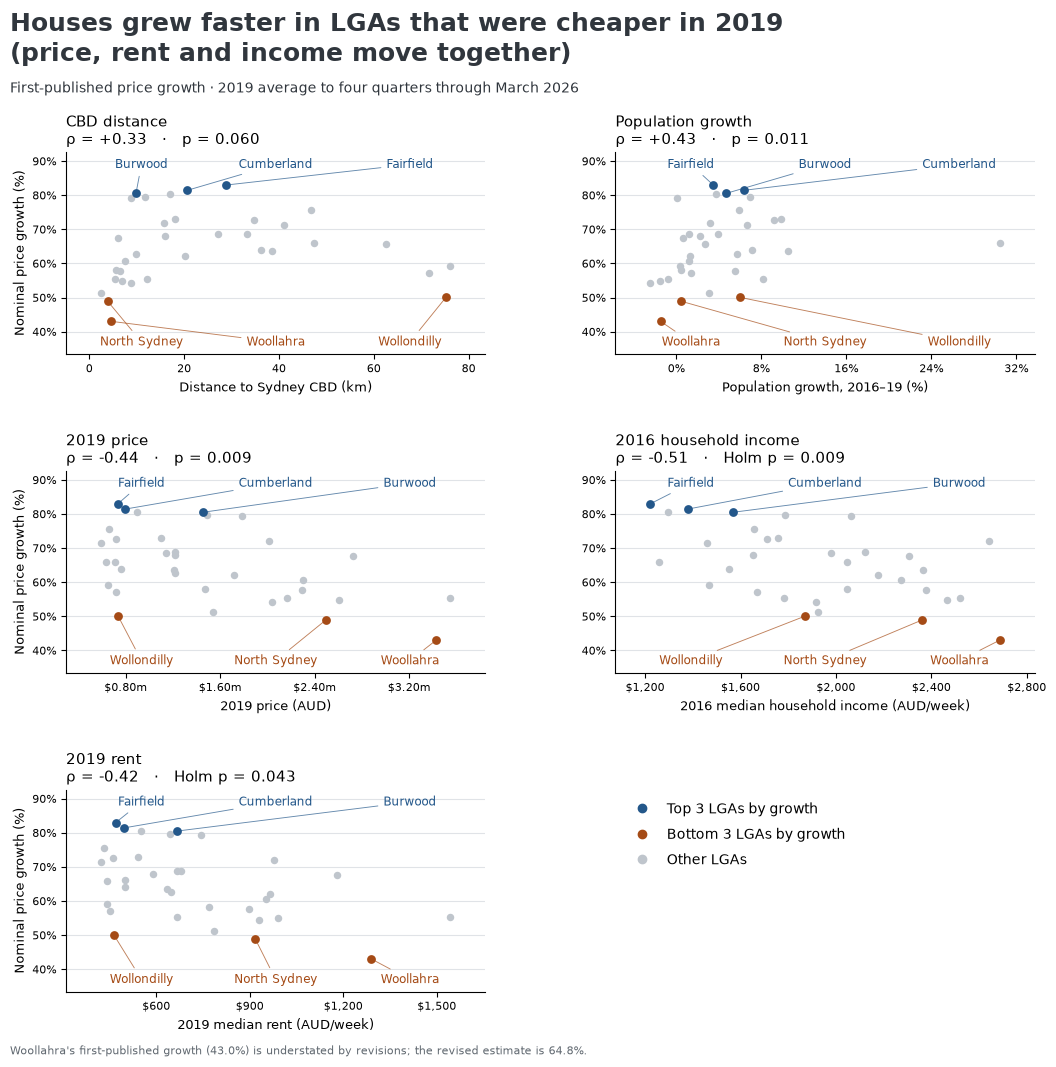

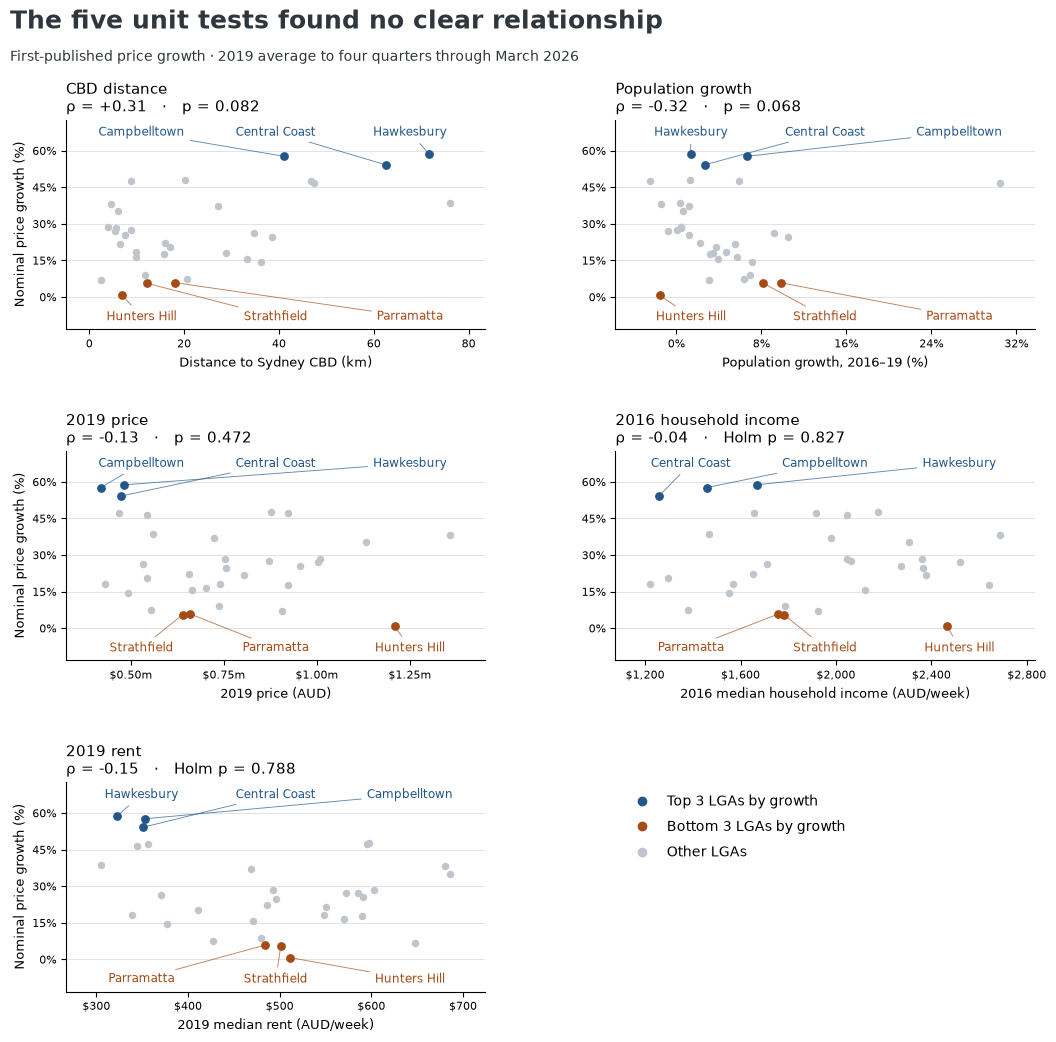

In [17]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

factor_axes = {
    "distance_km": ("Distance to Sydney CBD (km)", None),
    "pop_growth_2016_19": ("Population growth, 2016–19 (%)", PercentFormatter(1, decimals=0)),
    "price_2019": ("2019 price (AUD)", FuncFormatter(lambda x, pos: f"${x / 1_000_000:.2f}m")),
    "income_2016_weekly": ("2016 median household income (AUD/week)", FuncFormatter(lambda x, pos: f"${x:,.0f}")),
    "rent_2019_weekly": ("2019 median rent (AUD/week)", FuncFormatter(lambda x, pos: f"${x:,.0f}")),
}
scatter_titles = {
    "house": "Houses grew faster in LGAs that were cheaper in 2019 (price, rent and income move together)",
    "unit": "The five unit tests found no clear relationship",
}
scatter_tests = nominal_tests.set_index(test_keys)

def label_extremes(ax, points, factor, color, height):
    """Spread labels left to right in factor order so the connectors stay readable."""
    ordered = points.sort_values(factor)
    for x_text, (_, row) in zip([0.18, 0.50, 0.82], ordered.iterrows(), strict=True):
        ax.annotate(
            row["lga"], (row[factor], row["growth_pct"]), xytext=(x_text, height),
            textcoords="axes fraction", color=color, fontsize=8.4, ha="center", va="center",
            arrowprops={"arrowstyle": "-", "color": color, "lw": 0.65, "alpha": 0.7},
        )

def plot_factor_scatter(dwelling):
    data = factor_data.loc[factor_data["dwelling_type"].eq(dwelling)].sort_values("growth_rank")
    top_names = set(data.head(3)["lga"])
    bottom_names = set(data.tail(3)["lga"])
    low, high = data["growth_pct"].min(), data["growth_pct"].max()
    span = high - low
    fig, axes = plt.subplots(3, 2, figsize=(11.2, 10.9))
    title = scatter_titles[dwelling]
    axes_top = 0.875
    subtitle_y = 0.939
    if dwelling == "house":
        title = title.replace(" (", "\n(", 1)
        axes_top = 0.845
        subtitle_y = 0.91
    fig.subplots_adjust(left=0.10, right=0.965, top=axes_top, bottom=0.075, hspace=0.58, wspace=0.31)
    fig.text(0.05, 0.976, title, fontsize=18, fontweight="bold", color=ink, va="top")
    fig.text(
        0.05, subtitle_y, f"First-published price growth · 2019 average to four quarters through {end_label}",
        fontsize=10, color=ink, va="top",
    )
    for i, (ax, (factor, (x_label, formatter))) in enumerate(zip(axes.flat, factor_axes.items())):
        points = data.dropna(subset=[factor])
        top = points.loc[points["lga"].isin(top_names)]
        bottom = points.loc[points["lga"].isin(bottom_names)]
        other = points.loc[~points["lga"].isin(top_names | bottom_names)]
        ax.scatter(other[factor], other["growth_pct"], color=light_grey, s=29, linewidths=0)
        ax.scatter(top[factor], top["growth_pct"], color=blue, s=40, linewidths=0, zorder=3)
        ax.scatter(bottom[factor], bottom["growth_pct"], color=rust, s=40, linewidths=0, zorder=3)
        ax.set_ylim(low - 0.24 * span, high + 0.24 * span)
        ax.margins(x=0.10)
        label_extremes(ax, top, factor, blue, 0.94)
        label_extremes(ax, bottom, factor, rust, 0.06)

        test = scatter_tests.loc[(dwelling, factor)]
        p_label = f"Holm p = {test['p_holm']:.3f}" if test["family"] == "exploratory" else f"p = {test['p']:.3f}"
        ax.set_title(f"{factor_names[factor]}\nρ = {test['rho']:+.2f}   ·   {p_label}", loc="left", fontsize=10.5)
        ax.set_xlabel(x_label, fontsize=9)
        if i % 2 == 0:
            ax.set_ylabel("Nominal price growth (%)", fontsize=9)
        ax.yaxis.set_major_locator(MaxNLocator(6))
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.xaxis.set_major_locator(MaxNLocator(5))
        if formatter is not None:
            ax.xaxis.set_major_formatter(formatter)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", color=grid_grey)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    axes.flat[-1].axis("off")
    legend = [
        Line2D([], [], linestyle="none", marker="o", color=blue, label="Top 3 LGAs by growth"),
        Line2D([], [], linestyle="none", marker="o", color=rust, label="Bottom 3 LGAs by growth"),
        Line2D([], [], linestyle="none", marker="o", color=light_grey, label="Other LGAs"),
    ]
    axes.flat[-1].legend(handles=legend, loc="upper left", frameon=False, fontsize=10, labelspacing=0.8)
    if dwelling == "house":
        add_woollahra_footnote(fig, 0.05)
    save_chart(fig, f"factor_scatter_{dwelling}.png")

for dwelling in dwelling_types:
    plot_factor_scatter(dwelling)

### Show the overlaps in both dwelling types

Use the same colour scale in each panel, with grey for zero. Print the correlation in each cell so the values can be read directly.

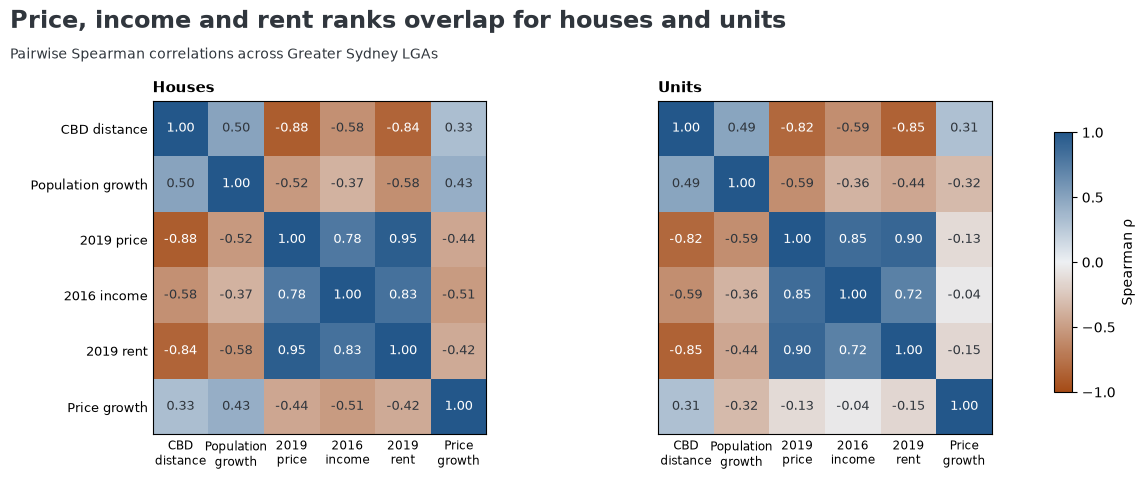

In [18]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

matrix_labels = ["CBD distance", "Population growth", "2019 price", "2016 income", "2019 rent", "Price growth"]
short_matrix_labels = ["CBD\ndistance", "Population\ngrowth", "2019\nprice", "2016\nincome", "2019\nrent", "Price\ngrowth"]
colour_map = LinearSegmentedColormap.from_list("spearman", [rust, "#EDF0F3", blue])
scale = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
fig, axes = plt.subplots(1, 2, figsize=(11.8, 5.3))
fig.subplots_adjust(left=0.14, right=0.903, bottom=0.16, top=0.79, wspace=0.28)
fig.text(0.045, 0.961, "Price, income and rent ranks overlap for houses and units",
         fontsize=17, fontweight="bold", color=ink, va="top")
fig.text(0.045, 0.89, "Pairwise Spearman correlations across Greater Sydney LGAs",
         fontsize=10, color=ink, va="top")

for ax, dwelling in zip(axes, dwelling_types, strict=True):
    matrix = overlap_matrices[dwelling]
    image = ax.imshow(matrix, cmap=colour_map, norm=scale)
    ax.set_title(dwelling.capitalize() + "s", loc="left", fontsize=11, fontweight="bold")
    ax.set_xticks(range(len(matrix_labels)), short_matrix_labels, fontsize=8.5)
    ax.set_yticks(range(len(matrix_labels)), matrix_labels if dwelling == "house" else [""] * len(matrix_labels), fontsize=9)
    ax.tick_params(length=0)
    for row in range(len(matrix_labels)):
        for col in range(len(matrix_labels)):
            rho = matrix.iloc[row, col]
            text_color = "white" if abs(rho) >= 0.67 else ink
            ax.text(col, row, f"{rho:.2f}", color=text_color, ha="center", va="center", fontsize=9)

colour_axis = fig.add_axes([0.93, 0.24, 0.015, 0.49])
colour_bar = fig.colorbar(image, cax=colour_axis, ticks=[-1, -0.5, 0, 0.5, 1])
colour_bar.set_label("Spearman ρ")
save_chart(fig, "factor_correlation.png")

### Findings from the factor tests

Summarise the ring counts, the strongest associations and the results that changed under D08. Use the planned verdict language and keep the baseline-price caveat visible.

In [19]:
house_tests = factor_results.loc[factor_results["dwelling_type"].eq("house")].set_index("factor")
unit_tests = factor_results.loc[factor_results["dwelling_type"].eq("unit")].set_index("factor")
house_population = house_tests.loc["pop_growth_2016_19"]
house_price = house_tests.loc["price_2019"]
house_income = house_tests.loc["income_2016_weekly"]
house_rent = house_tests.loc["rent_2019_weekly"]
price_rent_overlap = overlap_matrices["house"].loc["price_2019", "rent_2019_weekly"]
assert unit_tests["verdict"].eq("no clear relationship").all()
assert set(factor_results.loc[factor_results["verdict_changed"], "factor"]) == {
    "pop_growth_2016_19", "price_2019", "rent_2019_weekly",
}
factor_findings = (
    f"{top_ten_by_ring.loc['Middle Ring', 'House top ten']} of the ten fastest-growing house LGAs were in the "
    f"Middle Ring ({top_ten_by_ring.loc['Middle Ring', 'All LGAs']} LGAs total), and "
    f"{top_ten_by_ring.loc['Outer Ring', 'Unit top ten']} of the ten fastest-growing unit LGAs were in the "
    f"Outer Ring ({top_ten_by_ring.loc['Outer Ring', 'All LGAs']} total). "
    f"First-published house growth had a {house_population['verdict']} association with population growth "
    f"(ρ = {house_population['rho']:.2f}, p = {house_population['p']:.3f}) and a {house_price['verdict']} "
    f"association with 2019 price (ρ = {house_price['rho']:.2f}, p = {house_price['p']:.3f}), "
    "which is also the growth denominator. "
    f"Exploratory household income and house rent both had moderate negative associations with house growth "
    f"(Holm p = {house_income['p_holm']:.3f} and {house_rent['p_holm']:.3f}), and "
    f"2019 house price and rent ranked similarly (ρ = {price_rent_overlap:.2f}). "
    f"We tested CBD distance and found no clear relationship for houses or units "
    f"(p = {house_tests.loc['distance_km', 'p']:.3f} and {unit_tests.loc['distance_km', 'p']:.3f}), "
    "and all five unit tests had that verdict. "
    f"With revised house growth, population and rent had no clear relationship "
    f"(p = {house_population['p_rev']:.3f} and Holm p = {house_rent['p_holm_rev']:.3f}), "
    f"and the 2019 price association was {house_price['verdict_rev']} "
    f"(ρ = {house_price['rho_rev']:.2f}, p = {house_price['p_rev']:.3f})."
)
display(Markdown(factor_findings))

7 of the ten fastest-growing house LGAs were in the Middle Ring (12 LGAs total), and 8 of the ten fastest-growing unit LGAs were in the Outer Ring (14 total). First-published house growth had a moderate positive association with population growth (ρ = 0.43, p = 0.011) and a moderate negative association with 2019 price (ρ = -0.44, p = 0.009), which is also the growth denominator. Exploratory household income and house rent both had moderate negative associations with house growth (Holm p = 0.009 and 0.043), and 2019 house price and rent ranked similarly (ρ = 0.95). We tested CBD distance and found no clear relationship for houses or units (p = 0.060 and 0.082), and all five unit tests had that verdict. With revised house growth, population and rent had no clear relationship (p = 0.059 and Holm p = 0.166), and the 2019 price association was weak negative (ρ = -0.37, p = 0.032).